# A. YOLO11 Result Aggregation

`original` / `clahe` / `clahe_gamma` 학습 결과를 한 표·그래프로 집계합니다.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent
RUNS_DIR = PROJECT_DIR / 'runs' / 'detect'

PIPELINES = ['original', 'clahe', 'clahe_gamma']
RUN_PREFIX = 'yolo11n'

PIPELINE_META = {
    'original': {
        'role': '대조군 (Baseline)',
        'metric_summary': '원본 데이터',
        'expected_effect': '기본 탐지 성능 기준점',
    },
    'clahe': {
        'role': '실험군 1 (품질지표 1위)',
        'metric_summary': 'ROI 대비 +90%, 윤곽선 밀도 +223%',
        'expected_effect': '협착 경계선 검출력 극대화',
    },
    'clahe_gamma': {
        'role': '실험군 2 (품질지표 2위)',
        'metric_summary': 'ROI 대비 +80%, 윤곽선 밀도 +201%',
        'expected_effect': '대비 향상 + 밝기 균일화 효과 검증',
    },
}

print('RUNS_DIR:', RUNS_DIR)
print('exists  :', RUNS_DIR.exists())


RUNS_DIR: <PROJECT_ROOT>/runs/detect
exists  : True


In [2]:
# Parse results.csv from each run

def load_run_metrics(run_dir: Path) -> dict:
    out = {
        'run_dir': str(run_dir),
        'P': None,
        'R': None,
        'mAP50': None,
        'mAP50-95': None,
        'best_epoch': None,
    }

    csv_path = run_dir / 'results.csv'
    if not csv_path.exists():
        return out

    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    col_map = {
        'P': ['metrics/precision(B)', 'metrics/precision', 'precision'],
        'R': ['metrics/recall(B)', 'metrics/recall', 'recall'],
        'mAP50': ['metrics/mAP50(B)', 'metrics/mAP50', 'mAP50'],
        'mAP50-95': ['metrics/mAP50-95(B)', 'metrics/mAP50-95', 'mAP50-95'],
    }

    def find_col(keys):
        for k in keys:
            if k in df.columns:
                return k
        return None

    c_p = find_col(col_map['P'])
    c_r = find_col(col_map['R'])
    c_50 = find_col(col_map['mAP50'])
    c_95 = find_col(col_map['mAP50-95'])

    if c_95 is not None:
        best_idx = df[c_95].astype(float).idxmax()
        out['best_epoch'] = int(df.loc[best_idx, 'epoch']) if 'epoch' in df.columns else int(best_idx) + 1
        out['P'] = float(df.loc[best_idx, c_p]) if c_p else None
        out['R'] = float(df.loc[best_idx, c_r]) if c_r else None
        out['mAP50'] = float(df.loc[best_idx, c_50]) if c_50 else None
        out['mAP50-95'] = float(df.loc[best_idx, c_95])
    else:
        if c_p: out['P'] = float(df[c_p].iloc[-1])
        if c_r: out['R'] = float(df[c_r].iloc[-1])
        if c_50: out['mAP50'] = float(df[c_50].iloc[-1])
        if c_95: out['mAP50-95'] = float(df[c_95].iloc[-1])
    return out


rows = []
for p in PIPELINES:
    run_dir = RUNS_DIR / f'{RUN_PREFIX}_{p}'
    metrics = load_run_metrics(run_dir)
    meta = PIPELINE_META[p]
    rows.append({
        'pipeline': p,
        'role': meta['role'],
        'quant_summary': meta['metric_summary'],
        'expected_effect': meta['expected_effect'],
        **metrics,
        'exists': run_dir.exists(),
    })

df_cmp = pd.DataFrame(rows)
df_cmp


,pipeline,role,quant_summary,expected_effect,run_dir,P,R,mAP50,mAP50-95,best_epoch,exists
0,original,대조군 (Baseline),원본 데이터,기본 탐지 성능 기준점,<PROJECT_ROOT>/runs/detect/yolo11...,0.36436,0.38424,0.31933,0.12102,74,True
1,clahe,실험군 1 (품질지표 1위),"ROI 대비 +90%, 윤곽선 밀도 +223%",협착 경계선 검출력 극대화,<PROJECT_ROOT>/runs/detect/yolo11...,0.40338,0.36700,0.32000,0.12320,86,True
2,clahe_gamma,실험군 2 (품질지표 2위),"ROI 대비 +80%, 윤곽선 밀도 +201%",대비 향상 + 밝기 균일화 효과 검증,<PROJECT_ROOT>/runs/detect/yolo11...,0.37885,0.38609,0.32762,0.12703,90,True


In [3]:
# Manual override from validation logs
manual = {
    'original': {'P': 0.364, 'R': 0.387, 'mAP50': 0.320, 'mAP50-95': 0.121},
    'clahe': {'P': 0.381, 'R': 0.390, 'mAP50': 0.320, 'mAP50-95': 0.123},
    'clahe_gamma': {'P': 0.381, 'R': 0.387, 'mAP50': 0.330, 'mAP50-95': 0.127},
}

use_manual = True
if use_manual:
    for i, row in df_cmp.iterrows():
        p = row['pipeline']
        if p in manual:
            for k, v in manual[p].items():
                df_cmp.at[i, k] = v

df_cmp


,pipeline,role,quant_summary,expected_effect,run_dir,P,R,mAP50,mAP50-95,best_epoch,exists
0,original,대조군 (Baseline),원본 데이터,기본 탐지 성능 기준점,<PROJECT_ROOT>/runs/detect/yolo11...,0.364,0.387,0.32,0.121,74,True
1,clahe,실험군 1 (품질지표 1위),"ROI 대비 +90%, 윤곽선 밀도 +223%",협착 경계선 검출력 극대화,<PROJECT_ROOT>/runs/detect/yolo11...,0.381,0.390,0.32,0.123,86,True
2,clahe_gamma,실험군 2 (품질지표 2위),"ROI 대비 +80%, 윤곽선 밀도 +201%",대비 향상 + 밝기 균일화 효과 검증,<PROJECT_ROOT>/runs/detect/yolo11...,0.381,0.387,0.33,0.127,90,True


In [4]:
# Delta vs baseline + ranking
base = df_cmp[df_cmp['pipeline'] == 'original'].iloc[0]

for col in ['P', 'R', 'mAP50', 'mAP50-95']:
    df_cmp[f'delta_{col}'] = df_cmp[col] - float(base[col])
    df_cmp[f'rel_{col}_%'] = (df_cmp[f'delta_{col}'] / float(base[col]) * 100.0).round(2)

df_rank = df_cmp.sort_values('mAP50-95', ascending=False).reset_index(drop=True)
df_rank['rank_mAP50-95'] = df_rank.index + 1

display_cols = [
    'rank_mAP50-95', 'pipeline', 'role',
    'P', 'R', 'mAP50', 'mAP50-95',
    'delta_mAP50-95', 'rel_mAP50-95_%',
]
print(df_rank[display_cols].to_string(index=False))

out_csv = Path.cwd() / 'yolo11n_pipeline_comparison.csv'
df_rank.to_csv(out_csv, index=False)
print('saved:', out_csv)
df_rank[display_cols]


 rank_mAP50-95    pipeline            role     P     R  mAP50  mAP50-95  delta_mAP50-95  rel_mAP50-95_%
             1 clahe_gamma 실험군 2 (품질지표 2위) 0.381 0.387   0.33     0.127           0.006            4.96
             2       clahe 실험군 1 (품질지표 1위) 0.381 0.390   0.32     0.123           0.002            1.65
             3    original  대조군 (Baseline) 0.364 0.387   0.32     0.121           0.000            0.00
saved: <PROJECT_ROOT>/notebooks/yolo11n_pipeline_comparison.csv


,rank_mAP50-95,pipeline,role,P,R,mAP50,mAP50-95,delta_mAP50-95,rel_mAP50-95_%
0,1,clahe_gamma,실험군 2 (품질지표 2위),0.381,0.387,0.33,0.127,0.006,4.96
1,2,clahe,실험군 1 (품질지표 1위),0.381,0.390,0.32,0.123,0.002,1.65
2,3,original,대조군 (Baseline),0.364,0.387,0.32,0.121,0.000,0.00


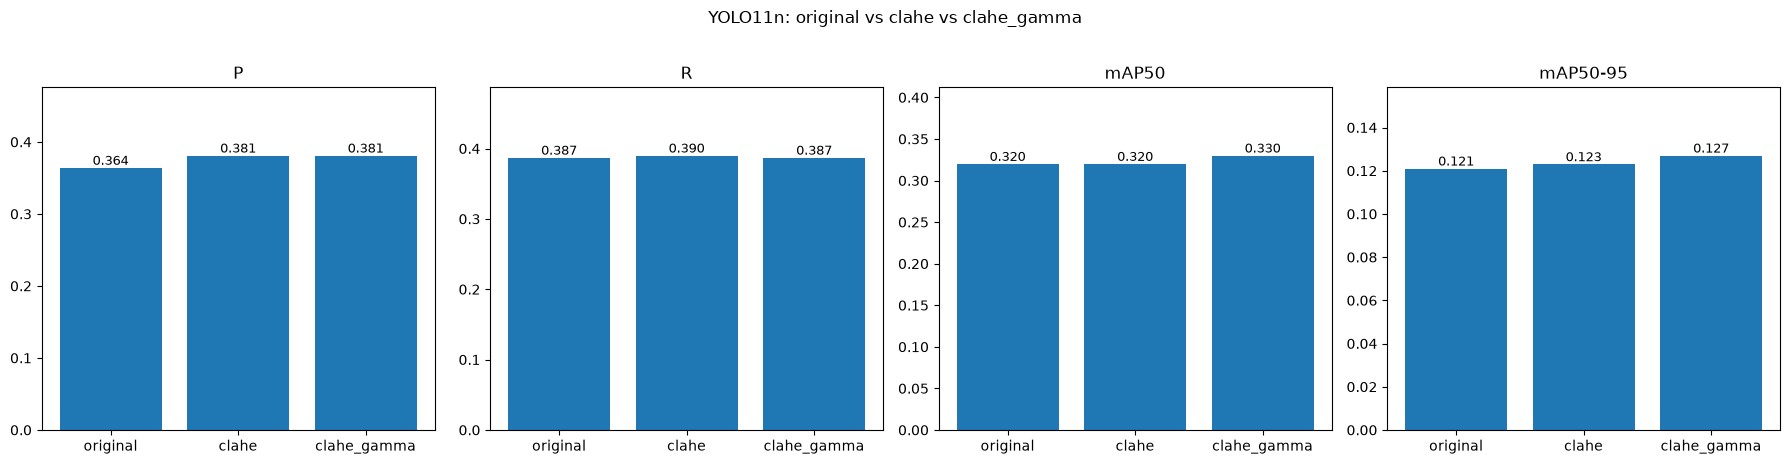

In [5]:
# Plots
metrics = ['P', 'R', 'mAP50', 'mAP50-95']
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

order = ['original', 'clahe', 'clahe_gamma']
plot_df = df_cmp.set_index('pipeline').loc[order].reset_index()

for ax, m in zip(axes, metrics):
    ax.bar(plot_df['pipeline'], plot_df[m])
    ax.set_title(m)
    ax.set_ylim(0, max(0.01, float(plot_df[m].max()) * 1.25))
    for i, v in enumerate(plot_df[m].tolist()):
        ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('YOLO11n: original vs clahe vs clahe_gamma', y=1.02)
plt.tight_layout()
plt.show()


In [6]:
winner = df_rank.iloc[0]['pipeline']
print(f'Winner by mAP50-95: {winner}')
print(df_rank.iloc[0][['pipeline', 'role', 'mAP50', 'mAP50-95', 'delta_mAP50-95', 'rel_mAP50-95_%']].to_string())


Winner by mAP50-95: clahe_gamma
pipeline              clahe_gamma
role              실험군 2 (품질지표 2위)
mAP50                        0.33
mAP50-95                    0.127
delta_mAP50-95              0.006
rel_mAP50-95_%               4.96
